# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

In [1]:
# Preliminares
import pandas as pd

from src.cat_modeling import cargar_datos_clean
from src.transform import categorizar_en_cuantiles, encontrar_columnas
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    top_correlaciones, pintar_violin_plots 
)

# Cargar fichero de precios
df_clean = cargar_datos_clean()

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 875 entries, 2007-04-30 to 2026-10-26
Data columns (total 88 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   AUDUSD_Close_return                             875 non-null    float64
 1   EURUSD_Close_return                             875 non-null    float64
 2   GBPUSD_Close_return                             875 non-null    float64
 3   USDCAD_Close_return                             875 non-null    float64
 4   USDCHF_Close_return                             875 non-null    float64
 5   USDJPY_Close_return                             875 non-null    float64
 6   EURUSD_Close_return_lag1                        875 non-null    float64
 7   GBPUSD_Close_return_lag1                        875 non-null    float64
 8   USDJPY_Close_return_lag1                        875 non-null    float64
 9   USDCHF_Close_return_lag1

## Analisis de variables

In [2]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

In [3]:
# Descripcion de variables
columnas_clean = df_clean.columns.tolist()
cadena = "Volume_pct_diff_sma20"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)

df_clean[columnas].describe().T

,count,mean,std,min,25%,50%,75%,max
Oil_Volume_pct_diff_sma20_lag1_yeo,875.0,-0.002380,0.998659,-3.688763,-0.598508,0.031070,0.650913,5.328833
Gold_Volume_pct_diff_sma20_lag1_yeo,875.0,0.000818,1.000851,-0.950563,-0.879645,-0.671339,0.912572,2.189942
SPY_Volume_pct_diff_sma20_lag1_yeo,875.0,0.000570,1.001001,-3.646471,-0.641664,-0.017217,0.656859,3.001652


In [4]:
# Asimetrias general
mostrar_asimetrias(df_clean)

USDCAD_Close_return                               2.854882
Oil_Close_max20_pct_diff_Close_lag1_log1p         2.832654
St_louis_financial_stress_lag1                    2.684910
SPY_Close_max20_pct_diff_Close_lag1_log1p         2.254915
VIX_index_lag1                                    2.017141
USDCAD_Close_var20_lag1_log                       2.013405
USDCAD_Close_max20_pct_diff_Close_lag1_log1p      1.824072
GBPUSD_High_Low_spread_lag1_log                   1.452373
EURUSD_Close_max20_pct_diff_Close_lag1_log1p      1.451298
Gold_Close_max20_pct_diff_Close_lag1_log1p        1.391379
GBPUSD_Close_max20_pct_diff_Close_lag1_log1p      1.367588
USDJPY_High_Low_spread_lag1_log                   1.366648
USDCHF_Close_max20_pct_diff_Close_lag1_log1p      1.325985
USDJPY_Close_max20_pct_diff_Close_lag1_log1p      1.134486
AUDUSD_Close_max20_pct_diff_Close_lag1_log1p      1.114343
USDCHF_Close_var20_lag1_log                       1.090623
EURUSD_High_Low_spread_lag1_log                   0.9234

In [5]:
# Asimetria por grupo
cadena = "Volume_pct_diff_sma20"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)
mostrar_asimetrias(df_clean[columnas])

Gold_Volume_pct_diff_sma20_lag1_yeo    0.580610
Oil_Volume_pct_diff_sma20_lag1_yeo    -0.016924
SPY_Volume_pct_diff_sma20_lag1_yeo    -0.038878


Cont


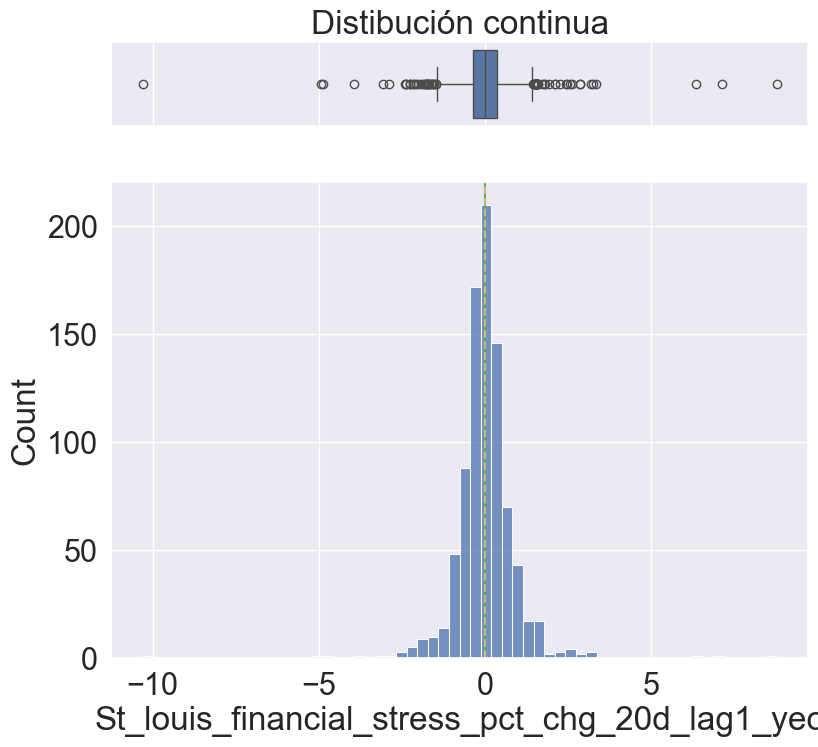

In [7]:
# Visualizar columna
col = 'St_louis_financial_stress_pct_chg_20d_lag1_yeo'
pintar_columna(df_clean[col])

In [8]:
# Tabla de Correlaciones
top_correlaciones(df=df_clean, top_n=30)

,Variable A,Variable B,correlation
363,USDCAD_Close_sma20_pct_diff_sma50_lag1,AUDUSD_Close_sma20_pct_diff_sma50_lag1,0.830826
1803,SPY_Close_max20_pct_diff_Close_lag1_log1p,VIX_index_lag1,0.808071
423,USDCHF_Close_sma20_pct_diff_sma50_lag1,EURUSD_Close_sma20_pct_diff_sma50_lag1,0.787934
2087,GBPUSD_High_pct_diff_Close_lag1_yeo,GBPUSD_Close_return_lag1,0.763516
1907,USDCHF_Close_max20_pct_diff_Close_lag1_log1p,EURUSD_Close_min20_pct_diff_Close_lag1,0.752706
2153,USDJPY_High_pct_diff_Close_lag1_yeo,USDJPY_Close_return_lag1,0.750827
2990,USDCHF_Low_pct_diff_Close_lag1_yeo,EURUSD_High_pct_diff_Close_lag1_yeo,0.747697
2696,EURUSD_Low_pct_diff_Close_lag1_yeo,USDCHF_High_pct_diff_Close_lag1_yeo,0.743342
1426,USDCHF_Close_var20_lag1_log,EURUSD_Close_var20_lag1_log,0.741927
1023,SPY_High_Low_spread_lag1_log,VIX_index_lag1,0.736240


## Analisis de labels

In [9]:
posibles_labels = [
    'AUDUSD_Close_return',
    'EURUSD_Close_return',
    'GBPUSD_Close_return',
    'USDCAD_Close_return',
    'USDCHF_Close_return',
    'USDJPY_Close_return'
    ]

objetivo = 'EURUSD_Close_return'
objetivo_cat = f"{objetivo}_cat"

df_clean, tabla_bins = categorizar_en_cuantiles(
    df_clean, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=False
    )

# Se eliminan las posibles labels continuas
df_clean = df_clean.drop(columns=posibles_labels)

print("\n--- Rangos por Categoría ---")
print(tabla_bins)


--- Rangos por Categoría ---
   categoria  lim_inferior  lim_superior
0          1     -0.042661     -0.004642
1          2     -0.004642      0.004592
2          3      0.004592      0.044001


In [10]:
df_clean[objetivo_cat].value_counts()

EURUSD_Close_return_cat
1    292
3    292
2    291
Name: count, dtype: int64

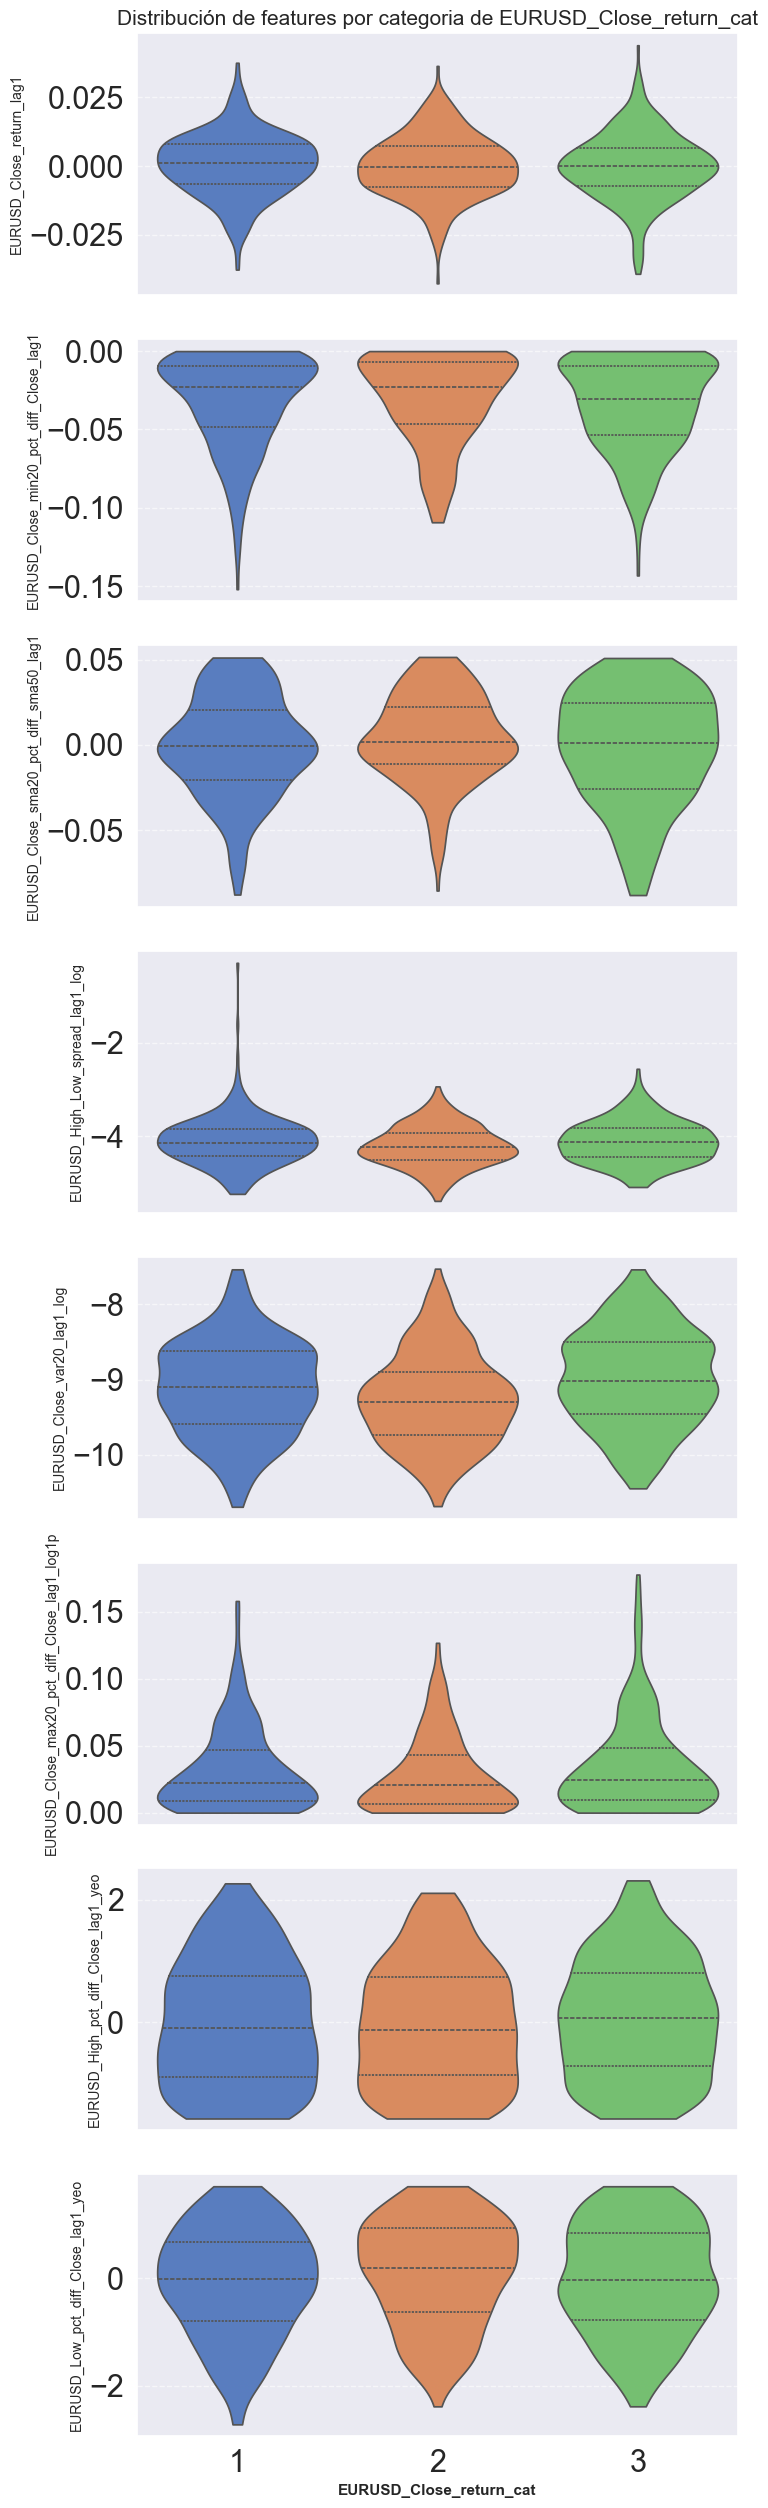

In [11]:
# Violin plot
# Identificar las variables numéricas excluyendo la variable objetivo
target_col = objetivo_cat
numeric_cols = df_clean.select_dtypes(include=["number"]).columns.tolist()

# Asegurar que la columna objetivo no esté en la lista
numeric_cols = [col for col in numeric_cols if col != target_col]

# Filtrar por grupo de variables
cadena = "EURUSD"
columnas = encontrar_columnas(columnas_target=numeric_cols, cadena=cadena)

pintar_violin_plots(
    df=df_clean,
    numeric_cols=columnas,
    target_col=target_col
)